In [30]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
df = pd.read_csv('apple_stock_data.csv', header=[0, 1], index_col=0, parse_dates=True)
df.index.name = 'Date'
df.columns.names = ['Num', 'Ticker']
df = df.stack(level='Ticker').reset_index()
df = df[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume']]
df.head()

Num,Date,Ticker,Open,High,Low,Close,Volume,Day of Week
0,2021-01-04,A,114.467823,115.574577,112.706630,114.179100,2030700.0,Monday
1,2021-01-04,AAPL,129.622521,129.709890,123.059845,125.632492,143301900.0,Monday
2,2021-01-04,ABBV,86.159128,86.295785,83.490269,84.736275,9523400.0,Monday
3,2021-01-04,ABNB,150.990005,151.005005,137.000000,139.149994,6409900.0,Monday
4,2021-01-04,ABT,98.245211,98.891031,96.209090,97.868484,6192000.0,Monday


Hypothesis Testing 1

H0 = The average Trading volume on down days is equal to or less than average trading volume on up days.

Ha = The average trading volume is signifcantly higher on down days compared to up days

3.02461560866332e-08
Reject the null hypothesis


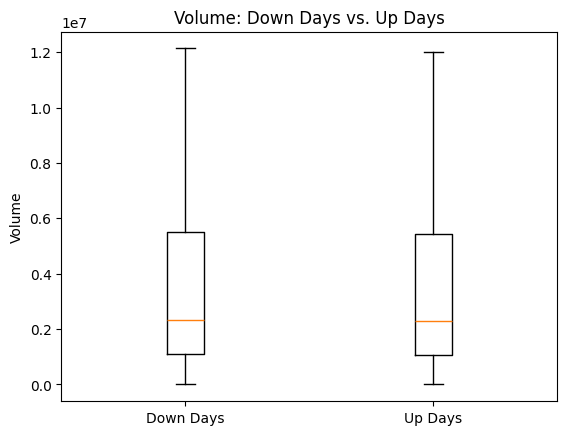

In [31]:
df['Day_Type'] = df.apply(lambda x: 'Down Day' if x['Close']<x['Open'] else 'Up Day', axis = 1)
vol_down = df[df['Day_Type'] == 'Down Day']['Volume'].dropna()
vol_up = df[df['Day_Type'] == 'Up Day']['Volume'].dropna()

# clean datetime, add day of week name
df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean["Day of Week"] = df_clean["Date"].dt.day_name()

u_stat, p_value = stats.mannwhitneyu(vol_down, vol_up, alternative='greater')
print(p_value)
if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis.")
plt.boxplot([vol_down, vol_up], tick_labels=['Down Days', 'Up Days'], showfliers=False)
plt.title("Volume: Down Days vs. Up Days")
plt.ylabel("Volume")
plt.show()

Use ANOVA testing to determine if there is a statistically significant difference depending on the day of the week.

H0 = There is no difference in the trading volume depending on the day of week

Ha = There is a difference in the trading volume depending on the day of week

In [37]:
from scipy.stats import f_oneway

volume = df_clean.groupby(["Ticker", "Day of Week"])["Volume"].mean().reset_index()
temp_storage = {"Ticker": [], "Statistic": [], "P-Value": []}
for ticker in df_clean["Ticker"].unique():
    stock = df_clean[df_clean["Ticker"] == ticker]
    anova = f_oneway(
        stock[stock["Day of Week"] == "Monday"]["Volume"],
        stock[stock["Day of Week"] == "Tuesday"]["Volume"],
        stock[stock["Day of Week"] == "Wednesday"]["Volume"],
        stock[stock["Day of Week"] == "Thursday"]["Volume"],
        stock[stock["Day of Week"] == "Friday"]["Volume"],
    )
    temp_storage["Ticker"].append(ticker)
    temp_storage["Statistic"].append(anova.statistic)
    temp_storage["P-Value"].append(anova.pvalue)
    
anova_df = pd.DataFrame(temp_storage)
significant = anova_df[anova_df["P-Value"] < 0.05]
display(anova_df.head())
print(f"Number of statistically significant results (pvalue < 0.05) / total results: {len(significant)} / {anova_df.shape[0]} = {len(significant)/anova_df.shape[0]}")

,Ticker,Statistic,P-Value
0,A,3.125971,0.014258
1,AAPL,6.224410,0.000058
2,ABBV,6.577079,0.000030
3,ABNB,2.624759,0.033254
4,ABT,2.073899,0.081947


Number of statistically significant results (pvalue < 0.05) / total results: 213 / 503 = 0.4234592445328032


So based on the results, we can see that for roughly 42.35% of the different companies, we can reject the null hypothesis and confirm that there is a difference in trading volume depending on the day of the week. For the other companies, we do not have enough evidence to conclude there is a difference and we fail to reject the null hypothesis.

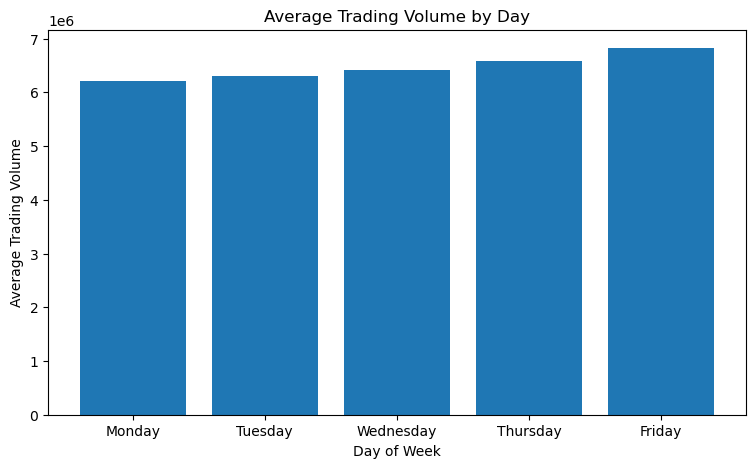

In [38]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
avg_volume = df_clean.groupby("Day of Week")["Volume"].mean()
avg_volume = avg_volume.reindex(days)

plt.figure(figsize=(9,5))
plt.bar(days, avg_volume)
plt.xlabel("Day of Week")
plt.ylabel("Average Trading Volume")
plt.title("Average Trading Volume by Day")
plt.show()

Use ANOVA testing to determine if there is a statistically significant difference depending on the day of the week.

H0 = There is no difference in the trading volume depending on the day of week

Ha = There is a difference in the trading volume depending on the day of week

In [37]:
from scipy.stats import f_oneway

volume = df_clean.groupby(["Ticker", "Day of Week"])["Volume"].mean().reset_index()
temp_storage = {"Ticker": [], "Statistic": [], "P-Value": []}
for ticker in df_clean["Ticker"].unique():
    stock = df_clean[df_clean["Ticker"] == ticker]
    anova = f_oneway(
        stock[stock["Day of Week"] == "Monday"]["Volume"],
        stock[stock["Day of Week"] == "Tuesday"]["Volume"],
        stock[stock["Day of Week"] == "Wednesday"]["Volume"],
        stock[stock["Day of Week"] == "Thursday"]["Volume"],
        stock[stock["Day of Week"] == "Friday"]["Volume"],
    )
    temp_storage["Ticker"].append(ticker)
    temp_storage["Statistic"].append(anova.statistic)
    temp_storage["P-Value"].append(anova.pvalue)
    
anova_df = pd.DataFrame(temp_storage)
significant = anova_df[anova_df["P-Value"] < 0.05]
display(anova_df.head())
print(f"Number of statistically significant results (pvalue < 0.05) / total results: {len(significant)} / {anova_df.shape[0]} = {len(significant)/anova_df.shape[0]}")

,Ticker,Statistic,P-Value
0,A,3.125971,0.014258
1,AAPL,6.224410,0.000058
2,ABBV,6.577079,0.000030
3,ABNB,2.624759,0.033254
4,ABT,2.073899,0.081947


Number of statistically significant results (pvalue < 0.05) / total results: 213 / 503 = 0.4234592445328032


So based on the results, we can see that for roughly 42.35% of the different companies, we can reject the null hypothesis and confirm that there is a difference in trading volume depending on the day of the week. For the other companies, we do not have enough evidence to conclude there is a difference and we fail to reject the null hypothesis.

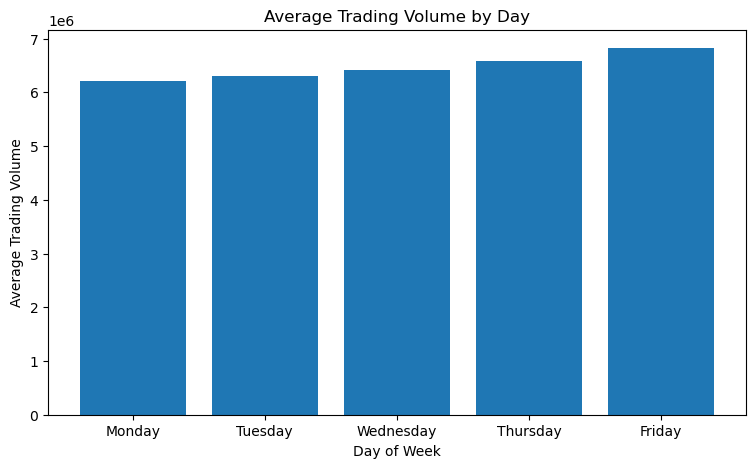

In [38]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
avg_volume = df_clean.groupby("Day of Week")["Volume"].mean()
avg_volume = avg_volume.reindex(days)

plt.figure(figsize=(9,5))
plt.bar(days, avg_volume)
plt.xlabel("Day of Week")
plt.ylabel("Average Trading Volume")
plt.title("Average Trading Volume by Day")
plt.show()